# 5. Piyasa genişliği ve yoğunlaşma

**Soru:** Nasdaq 100'ün yükselişini hisselerin çoğu mu taşıyor, yoksa birkaç dev şirket mi?

- **Genişlik:** hisselerin yüzde kaçı kendi 200 ve 50 günlük ortalamasının üstünde.
- **Yoğunlaşma:** endeks getirisinin ne kadarı en büyük 10 şirketten geliyor; eşit ağırlıklı sepetle fark.
- **Not:** Evren bugünkü Nasdaq 100; geçmişte çıkarılan zayıf hisseler yok (hayatta kalma yanlılığı).

In [1]:
import sys, sqlite3
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from mi import db, stats as st, events as ev, charts
%matplotlib inline
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
con = db.connect()
prices = pd.read_sql('SELECT * FROM prices', con)
close, volume = st.wide(prices), st.wide(prices, 'volume')
r = st.returns(close)
assets = pd.read_sql('SELECT * FROM assets', con).set_index('code')
print(f'{close.shape[1]} varlık, {close.index[0]:%Y-%m-%d} – {close.index[-1]:%Y-%m-%d}, {len(prices):,} fiyat satırı')

109 varlık, 2021-10-25 – 2026-10-23, 130,607 fiyat satırı


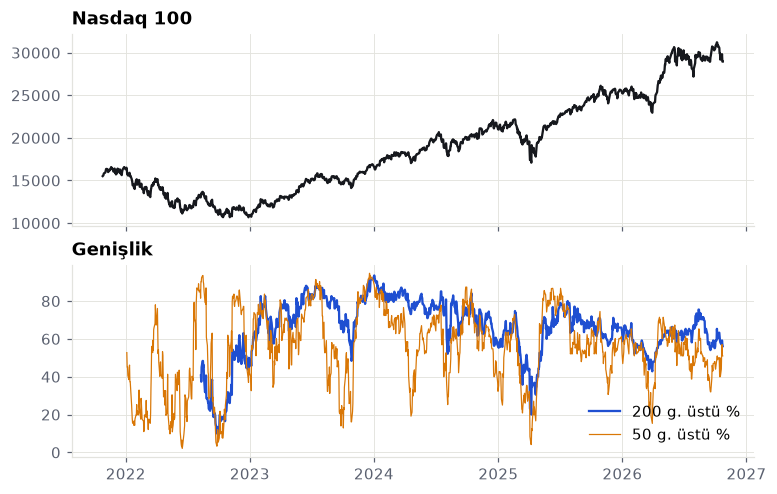

Bugün 200 g. üstü: %56, 50 g. üstü: %51


In [2]:
from mi import breadth as br
from mi.report import _mcap
stocks = assets.index[assets.cls == 'hisse'].tolist()
s = close[[c for c in stocks if c in close.columns]]
p200, p50 = br.above_ma(s, 200), br.above_ma(s, 50)
fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].plot(close['NDX'], color=charts.INK); ax[0].set_title('Nasdaq 100')
ax[1].plot(p200, color=charts.ACC, label='200 g. üstü %'); ax[1].plot(p50, color='#D97706', lw=.8, label='50 g. üstü %'); ax[1].legend(frameon=False)
ax[1].set_title('Genişlik'); plt.show()
print(f'Bugün 200 g. üstü: %{p200.iloc[-1]:.0f}, 50 g. üstü: %{p50.iloc[-1]:.0f}')

## Genişlik ile endeks getirisi arasındaki ilişki
Genişlik değişimi, sonraki 20 günlük endeks getirisiyle ilişkili mi? (Örtüşen pencereler yüzünden her 20 günde bir örnek alınıyor.)

51 bağımsız gözlem, Spearman ρ = -0.13, p = 0.348


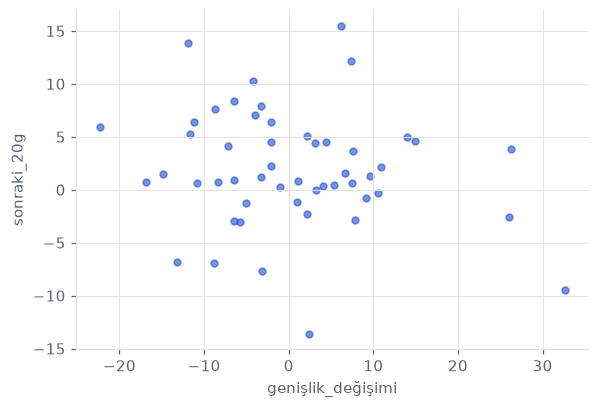

In [3]:
fwd = (close['NDX'].shift(-20) / close['NDX'] - 1) * 100
chg = p200 - p200.shift(20)
d = pd.DataFrame({'genişlik_değişimi': chg, 'sonraki_20g': fwd}).dropna().iloc[::20]
rho, p = stats.spearmanr(d['genişlik_değişimi'], d['sonraki_20g'])
print(f'{len(d)} bağımsız gözlem, Spearman ρ = {rho:.2f}, p = {p:.3f}')
d.plot.scatter('genişlik_değişimi', 'sonraki_20g', alpha=.6, color=charts.ACC, figsize=(6, 4)); plt.show()

## Yoğunlaşma: endeks getirisini kimler taşıdı?

In [4]:
mcap = pd.Series({c: _mcap(c) for c in s.columns}).dropna()
for d_, lab in ((63, '3 ay'), (252, '1 yıl')):
    c = br.contributions(s, mcap, d_)
    top = c.reindex(mcap.sort_values(ascending=False).index[:10]).dropna()
    print(f"{lab}: endeks ≈ %{c['contrib'].sum():.1f}, ilk 10 katkısı {top['contrib'].sum():.1f} puan, hisselerin %{(c['ret'] > 0).mean() * 100:.0f}'ı yükseldi")
br.contributions(s, mcap, 63).head(10)

3 ay: endeks ≈ %5.7, ilk 10 katkısı 5.5 puan, hisselerin %51'ı yükseldi
1 yıl: endeks ≈ %17.6, ilk 10 katkısı 10.5 puan, hisselerin %62'ı yükseldi


,contrib,ret,weight
code,,,
MSFT,2.60,35.05,7.42
SPCX,1.19,29.95,3.96
NVDA,0.91,7.47,12.17
TSLA,0.64,20.37,3.14
AMZN,0.46,7.18,6.42
AAPL,0.42,3.30,12.64
PLTR,0.40,49.59,0.81
META,0.32,8.29,3.89
CRWD,0.20,43.01,0.47


**Yorum:** İlk 10 şirketin katkısı endeks getirisinin büyük kısmıysa ve hisselerin azı yükseldiyse yükseliş dar tabanlıdır. Dar tabanlı yükselişler, öncü şirketlerden birinde kötü bir haber geldiğinde daha sert düzeltme riski taşır.